In [1]:
import grt_server
from PIL import Image
import numpy as np
from time import time


img = Image.open('../../docs/images/t3.png')

# Make a copy to compare between Mathematical Theory and Production-grade implementations
img_v = img.copy() 

In [2]:
M, N = 50, 100
a, b, c, d, rm, rn = grt_server.generate_valid_grt_keys(M, N)

a, b, c, d, rm, rn

(47, 0, 0, 27, 44, 24)

Image shape: (736, 1129)
Scrambling with M=50, N=100...
Image after being scrambled for 0.019s:


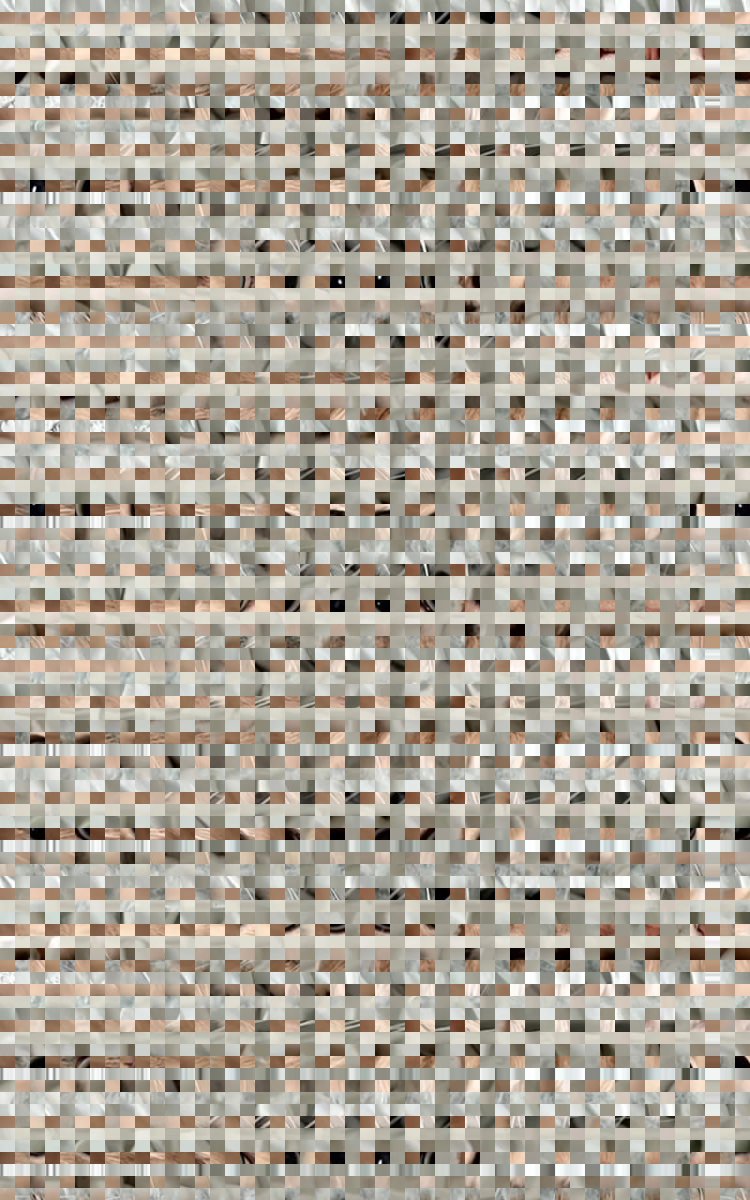

In [3]:
# Scalar forward GRT coordinate mapping

print(f"Image shape: {img.size}")
print(f"Scrambling with M={M}, N={N}...")

# Scrambling - Encryption
s = time()
scrambled_img = grt_server.scramble_image_grt(img, M, N, a, b, c, d, rm, rn, auto_pad = True)
e = time()
print(f"Image after being scrambled for {(e - s):.3f}s:")
display(scrambled_img)



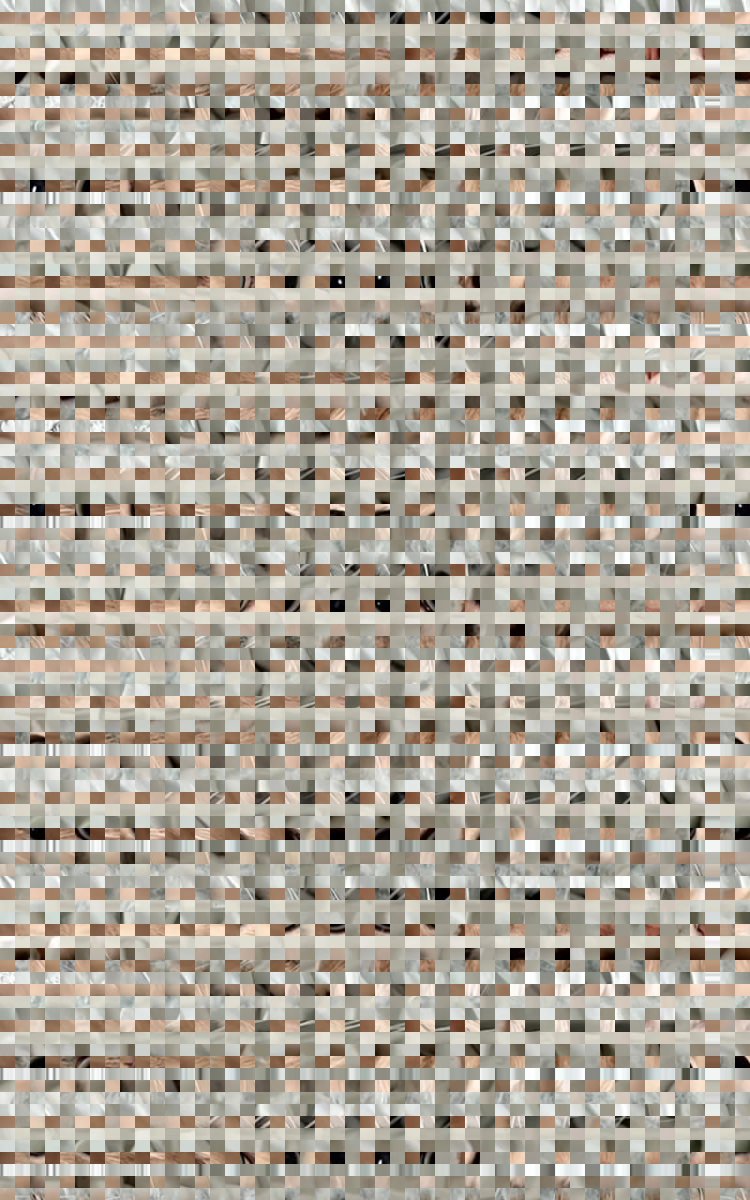

In [ ]:
# ### Client-Side JavaScript Decryption (HTML5 Canvas in Browser)

import base64
import io
from IPython.display import HTML, display

# 1. Extract original image dimensions (for unpadding / canvas cropping)
orig_w, orig_h = img.size

# 2. Encode scrambled image to base64 Data URI (simulating image network payload)
buffer = io.BytesIO()
scrambled_img.save(buffer, format="PNG")
img_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

# 3. Read client decryption library (src/cryptography/igrt_client.js)
with open("igrt_client.js", "r", encoding="utf-8") as f:
    js_code = f.read()

html_widget = f"""
<div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; background: #1e1e24; color: #f4f4f5; padding: 18px; border-radius: 8px; border: 1px solid #3f3f46; margin: 12px 0;">
  <div style="font-size: 14px; font-weight: 600; margin-bottom: 12px; color: #e4e4e7;">
    Client-Side Browser Execution via igrt_client.js (With Automatic Unpadding)
  </div>
  <div style="display: flex; gap: 20px; flex-wrap: wrap; align-items: flex-start;">
    <div>
      <div style="font-size: 12px; color: #a1a1aa; margin-bottom: 6px;">Ciphertext Payload (&lt;img&gt; with Padding: {scrambled_img.size[0]}x{scrambled_img.size[1]})</div>
      <img id="js_cipher_img" src="data:image/png;base64,{img_b64}" style="max-width: 320px; border: 1px solid #52525b; border-radius: 4px; display: block;" />
    </div>
    <div>
      <div style="font-size: 12px; color: #a1a1aa; margin-bottom: 6px;">Client Decrypted (&lt;canvas&gt; Cropped: {orig_w}x{orig_h})</div>
      <canvas id="js_plain_canvas" style="max-width: 320px; border: 1px solid #22c55e; border-radius: 4px; display: block;"></canvas>
    </div>
  </div>
  <div id="js_status_box" style="margin-top: 14px; font-size: 13px; color: #38bdf8;">
    Executing client JavaScript...
  </div>
</div>

<script>
{js_code}

(function() {{
  const img = document.getElementById("js_cipher_img");
  const canvas = document.getElementById("js_plain_canvas");
  const status = document.getElementById("js_status_box");

  function runClientDecryption() {{
    try {{
      const t0 = performance.now();
      // Pass decryption keys (M, N, a, b, c, d, rm, rn) and original unpadded dimensions (orig_w, orig_h)
      window.GRT.descrambleCanvasGRT(img, canvas, {M}, {N}, {a}, {b}, {c}, {d}, {rm}, {rn}, {orig_w}, {orig_h});
      const latency = (performance.now() - t0).toFixed(2);
      status.innerHTML = `<span style=\"color:#22c55e; font-weight:600;\">PASS:</span> Reconstructed losslessly on Canvas (${{canvas.width}}x${{canvas.height}}) in <strong>${{latency}} ms</strong> via <code>descrambleCanvasGRT</code>.`;
    }} catch (err) {{
      status.innerHTML = `<span style=\"color:#ef4444; font-weight:600;\">ERROR:</span> ${{err.message}}`;
    }}
  }}

  if (img.complete && img.naturalWidth > 0) {{
    runClientDecryption();
  }} else {{
    img.onload = runClientDecryption;
  }}
}})();
</script>
""" 

display(HTML(html_widget))
